In [1]:
pip install wget

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for wget: filename=wget-3.2-py3-none-any.whl size=9686 sha256=ae3a62ada566cc96f08722c6aa0bfb65239666be1d3df6bfbbb717755a0090ba
  Stored in directory: /root/.cache/pip/wheels/8a/b8/04/0c88fb22489b0c049bee4e977c5689c7fe597d6c4b0e7d0b6a
Successfully built wget


In [2]:
from pathlib import Path
import os
os.environ["KERAS_HOME"] = str(Path.cwd() / ".tools" / "keras")
import zipfile
import wget
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print("TensorFlow :", tf.__version__)
print("GPU :", gpus if gpus else "Tidak terdeteksi ; pelatihan menggunakan CPU.")
IMG_SIZE = (224, 224)
BATCH_SIZE = 16
EPOCHS = 10

TensorFlow : 2.21.0
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
url = "https://mymldatasets.s3.eu-de.cloud-object-storage.appdomain.cloud/UCMerced_LandUse.zip"
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
zip_path = data_dir / "UCMerced_LandUse.zip"

if not zip_path.exists():
    wget.download(url, out=str(zip_path))

with zipfile.ZipFile(zip_path) as arsip:
    for nama in arsip.namelist():
        tujuan = (data_dir / nama).resolve()
        if not tujuan.is_relative_to(data_dir.resolve()):
            raise ValueError("Lokasi file ZIP tidak valid")
    arsip.extractall(data_dir)

image_dir = data_dir / "dataset" / "Images"
print("Folder gambar :", image_dir)

Folder gambar : data/dataset/Images


In [4]:
url = "https://mymldatasets.s3.eu-de.cloud-object-storage.appdomain.cloud/UCMerced_LandUse.zip"
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
zip_path = data_dir / "UCMerced_LandUse.zip"

if not zip_path.exists():
    wget.download(url, out=str(zip_path))

with zipfile.ZipFile(zip_path) as arsip:
    for nama in arsip.namelist():
        tujuan = (data_dir / nama).resolve()
        if not tujuan.is_relative_to(data_dir.resolve()):
            raise ValueError("Lokasi file ZIP tidak valid")
    arsip.extractall(data_dir)

image_dir = data_dir / "dataset" / "Images"
print("Folder gambar :", image_dir)

# Memuat data gambar untuk mendefinisikan nama_kelas, X, dan y
nama_kelas = sorted([d.name for d in image_dir.iterdir() if d.is_dir()])
X = []
y = []

for label_idx, kelas in enumerate(nama_kelas):
    kelas_dir = image_dir / kelas
    for img_path in kelas_dir.glob("*.tif"):
        img = Image.open(img_path).resize(IMG_SIZE)
        X.append(np.array(img))
        y.append(label_idx)

X = np.array(X)
y = np.array(y)

# Memastikan kelengkapan dataset sesuai dengan assert
assert len(nama_kelas) == 21 and len(X) == 2100, \
" Periksa kelengkapan dataset "
assert np.all(np.bincount(y) == 100), \
" Setiap kelas seharusnya memiliki 100 gambar "
print(" Bentuk data :", X.shape)
print(" Kelas :", nama_kelas)

Folder gambar : data/dataset/Images
 Bentuk data : (2100, 224, 224, 3)
 Kelas : ['agricultural', 'airplane', 'baseballdiamond', 'beach', 'buildings', 'chaparral', 'denseresidential', 'forest', 'freeway', 'golfcourse', 'harbor', 'intersection', 'mediumresidential', 'mobilehomepark', 'overpass', 'parkinglot', 'river', 'runway', 'sparseresidential', 'storagetanks', 'tenniscourt']


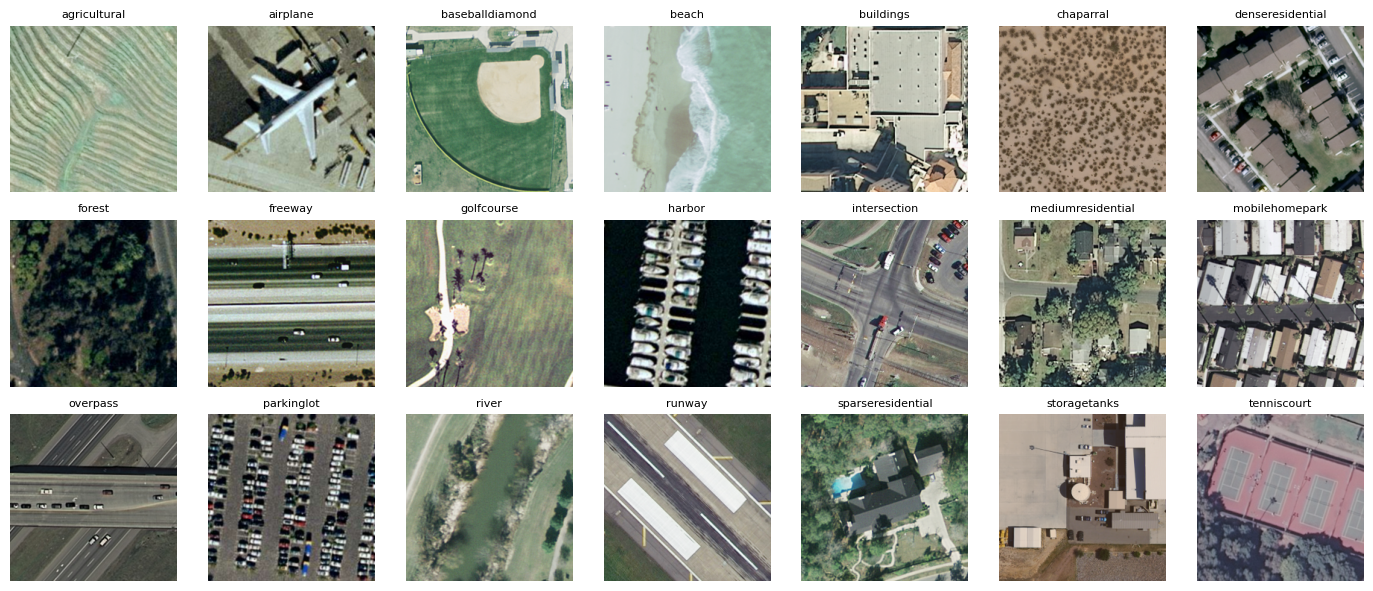

In [5]:
fig, axes = plt.subplots(3, 7, figsize=(14, 6))
for kelas, ax in enumerate(axes.flat):
    idx = np.flatnonzero(y == kelas)[0]
    ax.imshow(X[idx])
    ax.set_title(nama_kelas[kelas], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [6]:
x_train , x_sisa , y_train , y_sisa = train_test_split (
X ,
y ,
test_size =0.30 ,
stratify =y ,
random_state =42
)
x_val , x_test , y_val , y_test = train_test_split (
x_sisa ,
y_sisa ,
test_size =0.50 ,
stratify = y_sisa ,
random_state =42
)
print (
" Train :",
len ( y_train ) ,
" Validation :",
len ( y_val ) ,
" Test :",
len ( y_test )
)

 Train : 1470  Validation : 315  Test : 315


1. Gunakan arsitektur VGG untuk melatih data nya.

In [7]:
base_model = tf.keras.applications.VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE, 3)
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = tf.keras.applications.vgg16.preprocess_input(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(
    len(nama_kelas),
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs,
    outputs,
    name="vgg16_ucmerced"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()
print("Backbone dibekukan :", not base_model.trainable)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg16_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ input_layer_1[0]… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 512)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 21)        │     10,773 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,725,461 (56.17 MB)

 Trainable params: 10,773 (42.08 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Backbone dibekukan : True


In [8]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=2
)

print("Epoch dijalankan :", len(history.history["loss"]))

Epoch 1/10
92/92 - 21s - 229ms/step - accuracy: 0.2197 - loss: 5.6206 - val_accuracy: 0.5619 - val_loss: 2.0501
Epoch 2/10
92/92 - 7s - 72ms/step - accuracy: 0.5748 - loss: 1.9659 - val_accuracy: 0.7175 - val_loss: 1.0313
Epoch 3/10
92/92 - 7s - 73ms/step - accuracy: 0.7245 - loss: 1.1539 - val_accuracy: 0.7873 - val_loss: 0.6880
Epoch 4/10
92/92 - 7s - 73ms/step - accuracy: 0.8143 - loss: 0.7357 - val_accuracy: 0.8413 - val_loss: 0.5527
Epoch 5/10
92/92 - 7s - 74ms/step - accuracy: 0.8456 - loss: 0.5189 - val_accuracy: 0.8794 - val_loss: 0.4392
Epoch 6/10
92/92 - 7s - 74ms/step - accuracy: 0.8660 - loss: 0.4575 - val_accuracy: 0.8762 - val_loss: 0.4480
Epoch 7/10
92/92 - 7s - 75ms/step - accuracy: 0.8871 - loss: 0.3667 - val_accuracy: 0.8889 - val_loss: 0.3789
Epoch 8/10
92/92 - 7s - 75ms/step - accuracy: 0.9109 - loss: 0.2956 - val_accuracy: 0.9048 - val_loss: 0.3463
Epoch 9/10
92/92 - 7s - 76ms/step - accuracy: 0.9224 - loss: 0.2488 - val_accuracy: 0.9016 - val_loss: 0.3302
Epoch 10

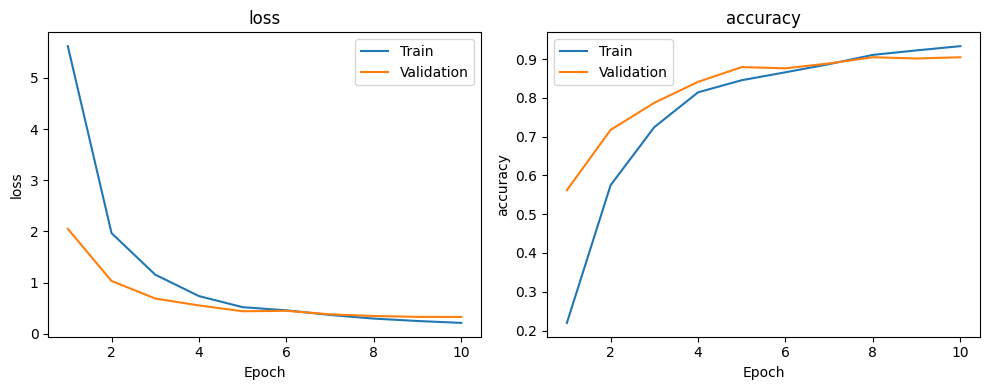

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
epochs = range(1, len(history.history["loss"]) + 1)

for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(
        epochs,
        history.history[metric],
        label="Train"
    )
    ax.plot(
        epochs,
        history.history["val_" + metric],
        label="Validation"
    )
    ax.set(
        xlabel="Epoch",
        ylabel=metric,
        title=metric
    )
    ax.legend()

plt.tight_layout()
plt.show()

Test loss : 0.2906 | Test accuracy : 91.75%
                   precision    recall  f1-score   support

     agricultural       1.00      0.93      0.97        15
         airplane       0.94      1.00      0.97        15
  baseballdiamond       1.00      0.87      0.93        15
            beach       1.00      1.00      1.00        15
        buildings       0.79      0.73      0.76        15
        chaparral       1.00      1.00      1.00        15
 denseresidential       0.73      0.53      0.62        15
           forest       0.88      1.00      0.94        15
          freeway       1.00      1.00      1.00        15
       golfcourse       1.00      0.93      0.97        15
           harbor       0.94      1.00      0.97        15
     intersection       1.00      0.93      0.97        15
mediumresidential       0.72      0.87      0.79        15
   mobilehomepark       0.94      1.00      0.97        15
         overpass       0.83      1.00      0.91        15
       park

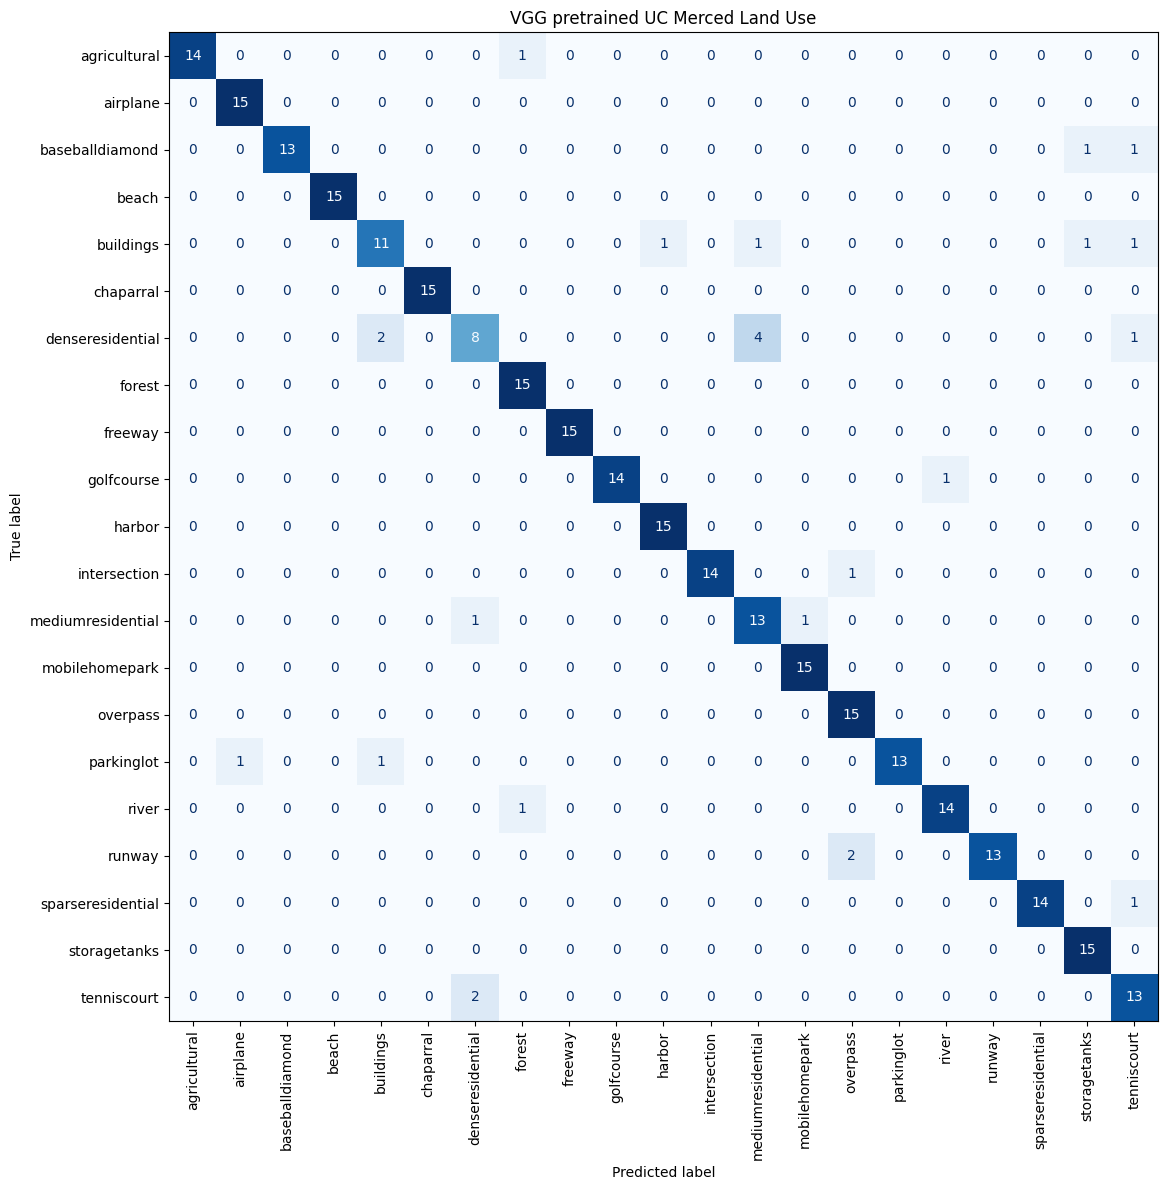

In [10]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

probabilitas = model.predict(
    x_test, batch_size=BATCH_SIZE,
    verbose=0
)

y_pred = probabilitas.argmax(axis=1)

print(
    f"Test loss : {test_loss:.4f} | "
    f"Test accuracy : {test_acc:.2%}"
)

assert np.isclose(
    test_acc,
    np.mean(y_pred == y_test),
    atol=1e-6
)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=nama_kelas,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=nama_kelas,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    ax=ax
)

ax.set_title("VGG pretrained UC Merced Land Use")
plt.tight_layout()
plt.show()

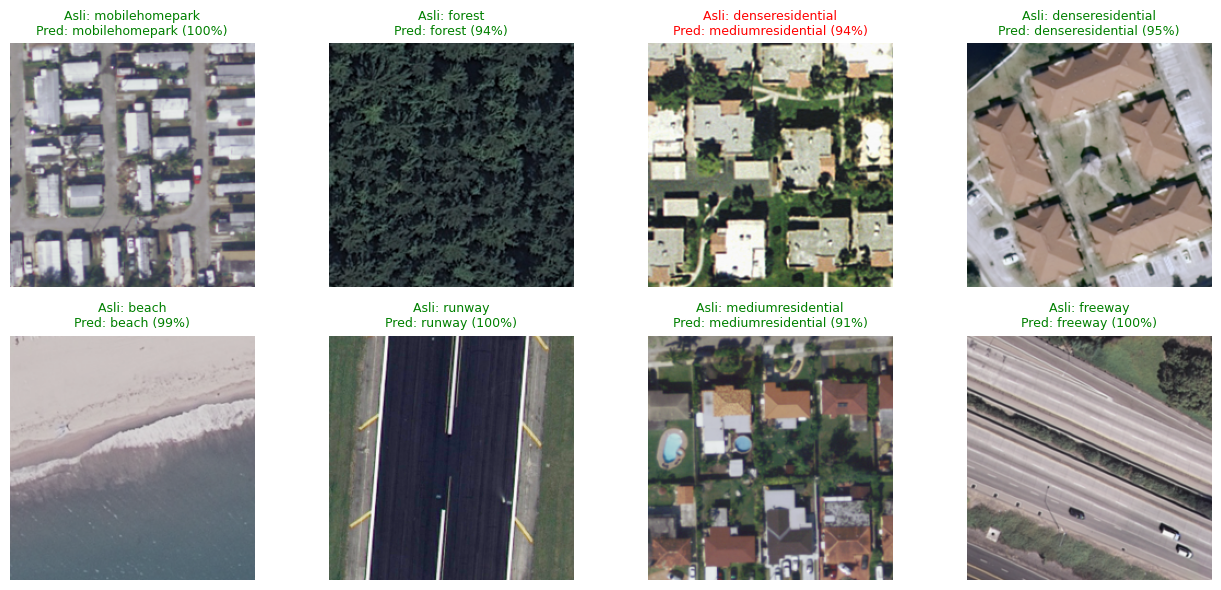

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i])
    ax.set_title(
        f"Asli: {nama_kelas[y_test[i]]}\n"
        f"Pred: {nama_kelas[y_pred[i]]} "
        f"({probabilitas[i].max():.0%})",
        fontsize=9,
        color="green" if y_test[i] == y_pred[i] else "red"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

2. Gunakan arsitektur lain (AlexNet, MobileNet, dsb) untuk melatih data nya.


a. mobilenet

In [12]:
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(*IMG_SIZE, 3)
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    len(nama_kelas),
    activation="softmax"
)(x)

model = tf.keras.Model(
    inputs,
    outputs,
    name="mobilenetv2_ucmerced"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()
print("Backbone dibekukan :", not base_model.trainable)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 21)             │        26,901 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,284,885 (8.72 MB)

 Trainable params: 26,901 (105.08 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Backbone dibekukan : True


In [13]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=2
)

print("Epoch dijalankan :", len(history.history["loss"]))

Epoch 1/10
92/92 - 25s - 273ms/step - accuracy: 0.5306 - loss: 1.5793 - val_accuracy: 0.8889 - val_loss: 0.5042
Epoch 2/10
92/92 - 22s - 238ms/step - accuracy: 0.9007 - loss: 0.3681 - val_accuracy: 0.9397 - val_loss: 0.3270
Epoch 3/10
92/92 - 2s - 19ms/step - accuracy: 0.9551 - loss: 0.2002 - val_accuracy: 0.9365 - val_loss: 0.2749
Epoch 4/10
92/92 - 2s - 18ms/step - accuracy: 0.9667 - loss: 0.1433 - val_accuracy: 0.9460 - val_loss: 0.2377
Epoch 5/10
92/92 - 2s - 19ms/step - accuracy: 0.9830 - loss: 0.1029 - val_accuracy: 0.9460 - val_loss: 0.2212
Epoch 6/10
92/92 - 2s - 19ms/step - accuracy: 0.9898 - loss: 0.0751 - val_accuracy: 0.9429 - val_loss: 0.2123
Epoch 7/10
92/92 - 2s - 18ms/step - accuracy: 0.9912 - loss: 0.0636 - val_accuracy: 0.9365 - val_loss: 0.1972
Epoch 8/10
92/92 - 2s - 18ms/step - accuracy: 0.9939 - loss: 0.0528 - val_accuracy: 0.9492 - val_loss: 0.1888
Epoch 9/10
92/92 - 2s - 24ms/step - accuracy: 0.9946 - loss: 0.0466 - val_accuracy: 0.9460 - val_loss: 0.1870
Epoch 

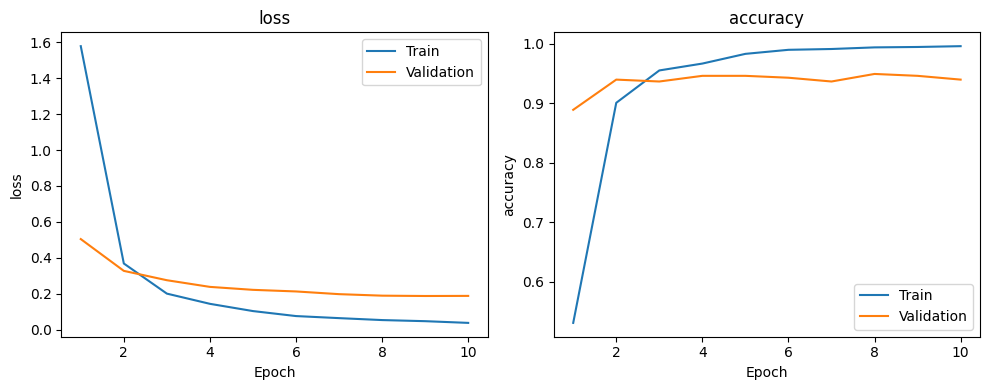

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
epochs = range(1, len(history.history["loss"]) + 1)

for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(
        epochs,
        history.history[metric],
        label="Train"
    )
    ax.plot(
        epochs,
        history.history["val_" + metric],
        label="Validation"
    )
    ax.set(
        xlabel="Epoch",
        ylabel=metric,
        title=metric
    )
    ax.legend()

plt.tight_layout()
plt.show()

Test loss : 0.1502 | Test accuracy : 96.51%
                   precision    recall  f1-score   support

     agricultural       1.00      1.00      1.00        15
         airplane       0.93      0.93      0.93        15
  baseballdiamond       1.00      1.00      1.00        15
            beach       1.00      1.00      1.00        15
        buildings       0.88      0.93      0.90        15
        chaparral       1.00      1.00      1.00        15
 denseresidential       0.82      0.93      0.88        15
           forest       1.00      1.00      1.00        15
          freeway       1.00      0.87      0.93        15
       golfcourse       1.00      1.00      1.00        15
           harbor       1.00      1.00      1.00        15
     intersection       1.00      0.87      0.93        15
mediumresidential       1.00      0.93      0.97        15
   mobilehomepark       1.00      1.00      1.00        15
         overpass       0.79      1.00      0.88        15
       park

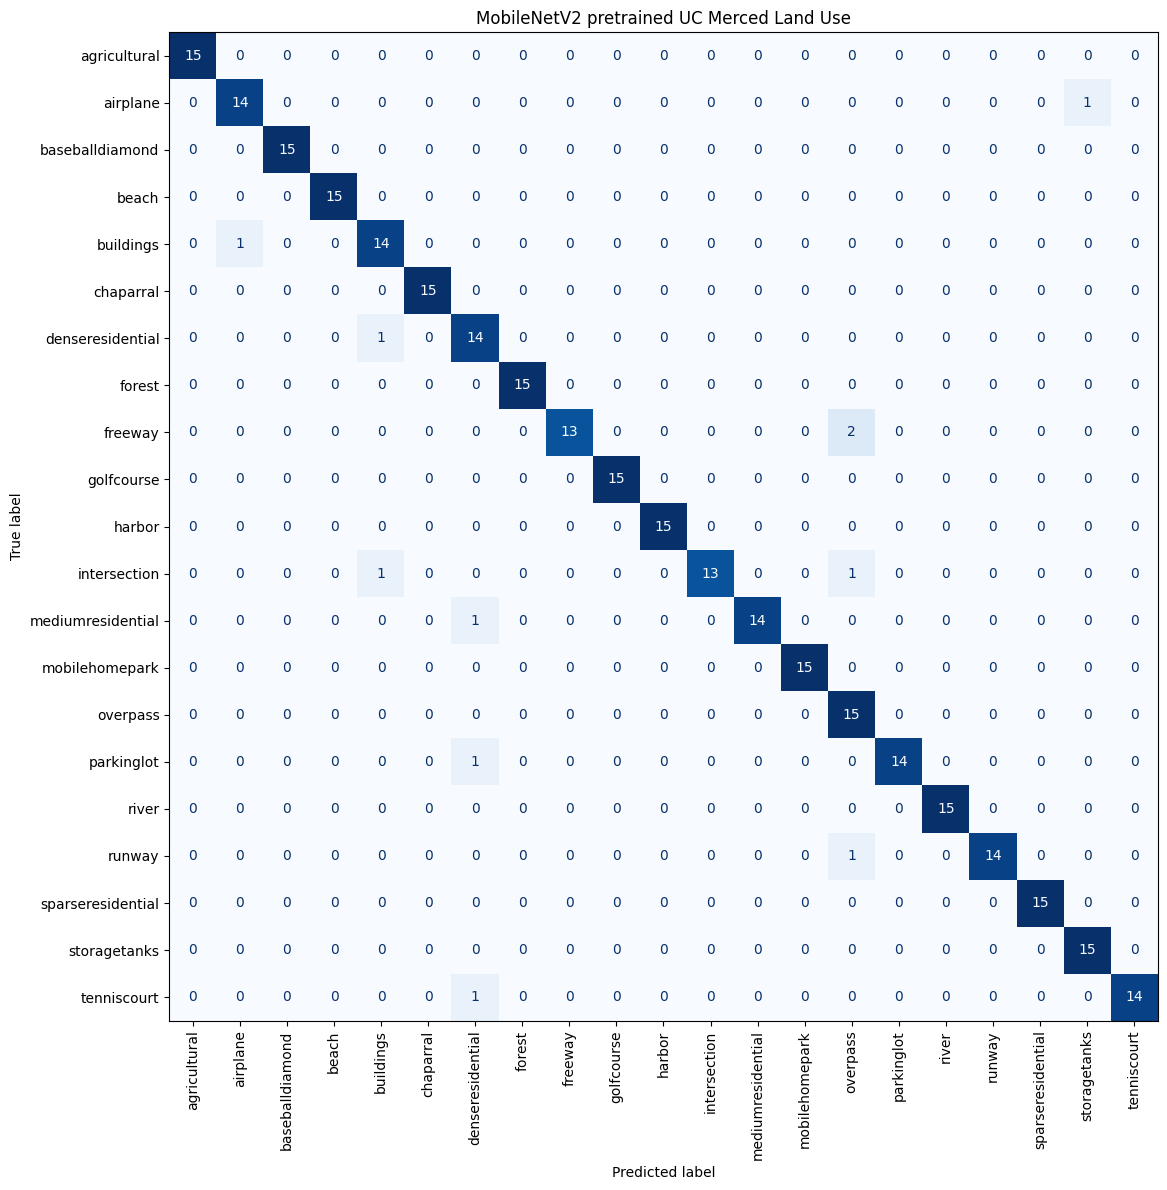

In [15]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

probabilitas = model.predict(
    x_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

y_pred = probabilitas.argmax(axis=1)

print(
    f"Test loss : {test_loss:.4f} | "
    f"Test accuracy : {test_acc:.2%}"
)

assert np.isclose(
    test_acc,
    np.mean(y_pred == y_test),
    atol=1e-6
)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=nama_kelas,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=nama_kelas,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    ax=ax
)

ax.set_title("MobileNetV2 pretrained UC Merced Land Use")
plt.tight_layout()
plt.show()

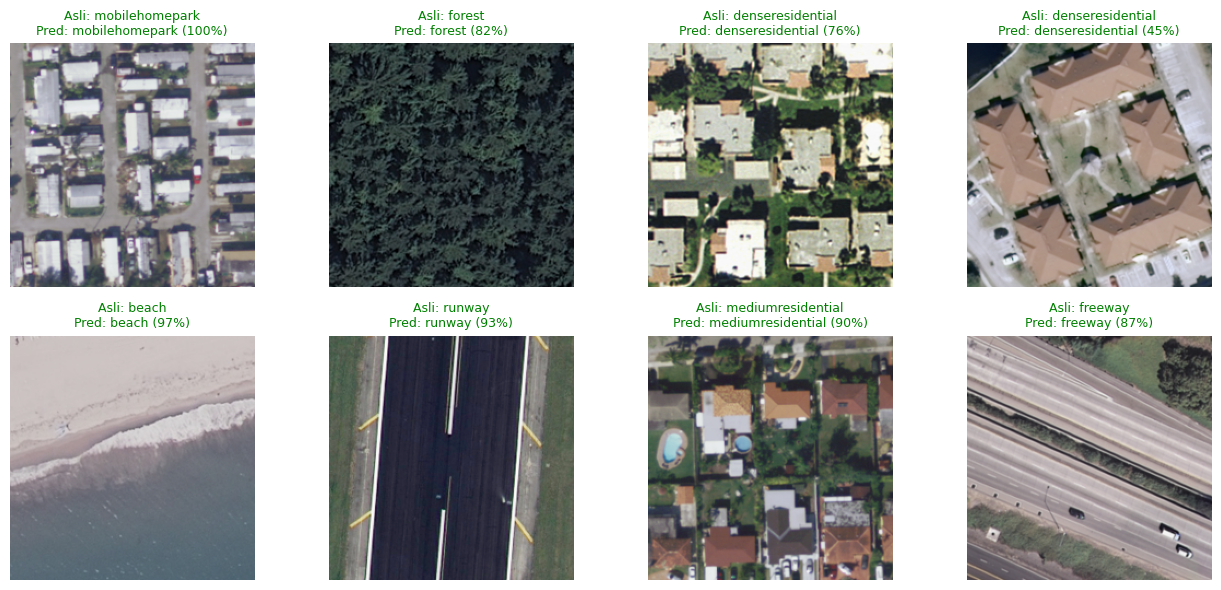

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i])
    ax.set_title(
        f"Asli: {nama_kelas[y_test[i]]}\n"
        f"Pred: {nama_kelas[y_pred[i]]} "
        f"({probabilitas[i].max():.0%})",
        fontsize=9,
        color="green" if y_test[i] == y_pred[i] else "red"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

b. Alexnet

In [17]:
inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))

# Convolutional layer 1
x = tf.keras.layers.Conv2D(
    96, kernel_size=11, strides=4,
    activation="relu", padding="valid"
)(inputs)
x = tf.keras.layers.MaxPooling2D(
    pool_size=3, strides=2
)(x)

# Convolutional layer 2
x = tf.keras.layers.Conv2D(
    256, kernel_size=5,
    activation="relu", padding="same"
)(x)
x = tf.keras.layers.MaxPooling2D(
    pool_size=3, strides=2
)(x)

# Convolutional layers 3, 4, and 5
x = tf.keras.layers.Conv2D(
    384, kernel_size=3,
    activation="relu", padding="same"
)(x)

x = tf.keras.layers.Conv2D(
    384, kernel_size=3,
    activation="relu", padding="same"
)(x)

x = tf.keras.layers.Conv2D(
    256, kernel_size=3,
    activation="relu", padding="same"
)(x)
x = tf.keras.layers.MaxPooling2D(
    pool_size=3, strides=2
)(x)

# Flatten and fully connected layers
x = tf.keras.layers.Flatten()(x)

x = tf.keras.layers.Dense(
    4096, activation="relu"
)(x)
x = tf.keras.layers.Dropout(0.5)(x)

x = tf.keras.layers.Dense(
    4096, activation="relu"
)(x)
x = tf.keras.layers.Dropout(0.5)(x)

# Output layer
outputs = tf.keras.layers.Dense(
    len(nama_kelas),
    activation="softmax"
)(x)

# Build model
model = tf.keras.Model(
    inputs,
    outputs,
    name="alexnet_ucmerced"
)

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "alexnet_ucmerced"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4096)           │    26,218,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 21)             │        86,037 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,833,045 (178.65 MB)

 Trainable params: 46,833,045 (178.65 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop],
    verbose=2
)

print("Epoch dijalankan :", len(history.history["loss"]))

Epoch 1/10
92/92 - 24s - 264ms/step - accuracy: 0.0483 - loss: 7.6085 - val_accuracy: 0.0476 - val_loss: 3.0449
Epoch 2/10
92/92 - 3s - 31ms/step - accuracy: 0.0408 - loss: 3.0471 - val_accuracy: 0.0508 - val_loss: 3.0443
Epoch 3/10
92/92 - 3s - 28ms/step - accuracy: 0.0374 - loss: 3.0553 - val_accuracy: 0.0476 - val_loss: 3.0447
Epoch 4/10
92/92 - 3s - 28ms/step - accuracy: 0.0401 - loss: 3.0477 - val_accuracy: 0.0476 - val_loss: 3.0446
Epoch 5/10
92/92 - 3s - 28ms/step - accuracy: 0.0293 - loss: 3.0473 - val_accuracy: 0.0476 - val_loss: 3.0446
Epoch dijalankan : 5


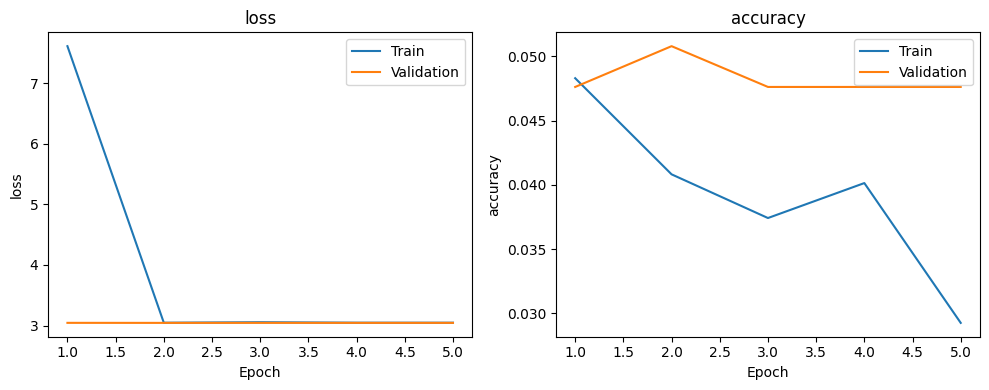

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
epochs = range(1, len(history.history["loss"]) + 1)

for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(
        epochs,
        history.history[metric],
        label="Train"
    )
    ax.plot(
        epochs,
        history.history["val_" + metric],
        label="Validation"
    )
    ax.set(
        xlabel="Epoch",
        ylabel=metric,
        title=metric
    )
    ax.legend()

plt.tight_layout()
plt.show()

Test loss : 3.0422 | Test accuracy : 4.44%
                   precision    recall  f1-score   support

     agricultural       0.00      0.00      0.00        15
         airplane       0.00      0.00      0.00        15
  baseballdiamond       0.00      0.00      0.00        15
            beach       0.00      0.00      0.00        15
        buildings       0.00      0.00      0.00        15
        chaparral       0.00      0.00      0.00        15
 denseresidential       0.00      0.00      0.00        15
           forest       0.00      0.00      0.00        15
          freeway       0.00      0.00      0.00        15
       golfcourse       0.00      0.00      0.00        15
           harbor       0.00      0.00      0.00        15
     intersection       0.05      0.93      0.09        15
mediumresidential       0.00      0.00      0.00        15
   mobilehomepark       0.00      0.00      0.00        15
         overpass       0.00      0.00      0.00        15
       parki

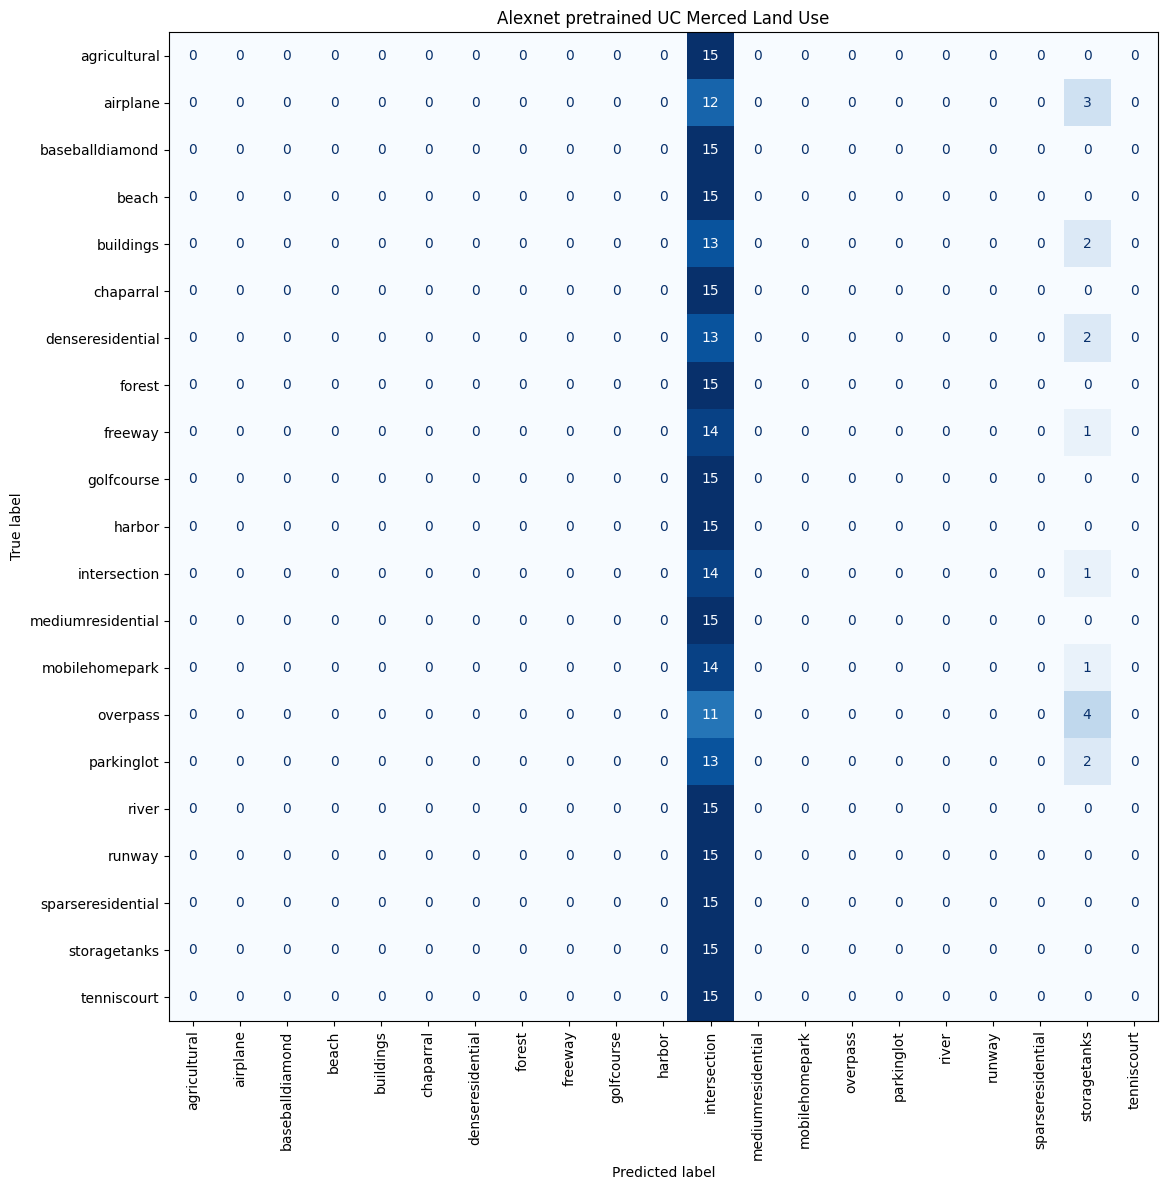

In [20]:
test_loss, test_acc = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

probabilitas = model.predict(
    x_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

y_pred = probabilitas.argmax(axis=1)

print(
    f"Test loss : {test_loss:.4f} | "
    f"Test accuracy : {test_acc:.2%}"
)

assert np.isclose(
    test_acc,
    np.mean(y_pred == y_test),
    atol=1e-6
)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=nama_kelas,
        zero_division=0
    )
)

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=nama_kelas,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    ax=ax
)

ax.set_title("Alexnet pretrained UC Merced Land Use")
plt.tight_layout()
plt.show()

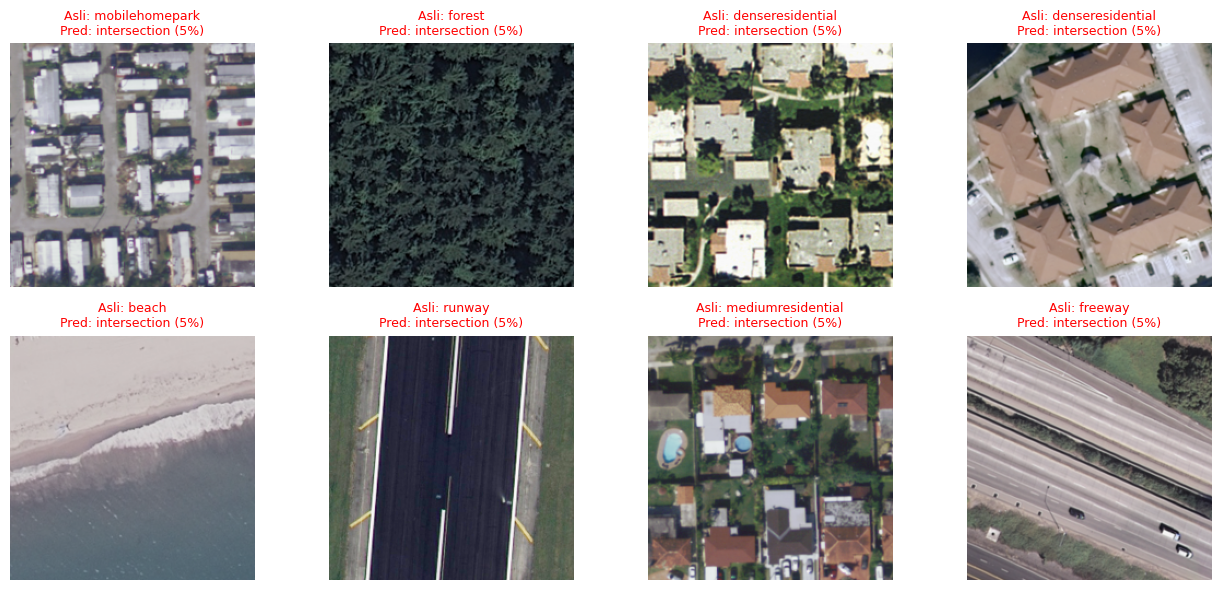

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i])
    ax.set_title(
        f"Asli: {nama_kelas[y_test[i]]}\n"
        f"Pred: {nama_kelas[y_pred[i]]} "
        f"({probabilitas[i].max():.0%})",
        fontsize=9,
        color="green" if y_test[i] == y_pred[i] else "red"
    )
    ax.axis("off")
plt.tight_layout()
plt.show()